# Power-Stress-2 data pipeline
In this notebook we analyze the results from run1, run2, run3 and run4

In [112]:
import pandas as pd
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [113]:
from analysis_functions import get_time_periods, get_power_data, divide_power_data_into_step_periods, compute_relative_energy_usage
from analysis_functions import plot_energy_usage, plot_multiple_datasets, plot_energy_usage_overlay_multiple_datasets

In [114]:
base_path = "../../data/power-stress-2"
corresponding_datasets = {
    "run1": {
        "simpipe": f"{base_path}/run1.dat", 
        "tapo": f'{base_path}/power-run1.xls',
        "start_time_baseline": '2026-09-28 00:00:00', 
        "end_time_baseline": '2026-09-28 10:26:33',
        "start_time_pipeline": '2026-09-28 10:26:33',
        "end_time_pipeline": '2026-09-28 13:26:37'},
    "run2": {
        "simpipe": f"{base_path}/run2.dat", 
        "tapo": f'{base_path}/power-run2.xls',
        "start_time_baseline": '2026-09-28 18:30:00', 
        "end_time_baseline": '2026-09-29 06:00:00',
        "start_time_pipeline": '2026-09-28 15:26:33',
        "end_time_pipeline": '2026-09-28 18:26:33'},
    "run3": {
        "simpipe": f"{base_path}/run3.dat", 
        "tapo": f'{base_path}/power-run3.xls',
        "start_time_baseline": '2026-09-28 20:00:00', 
        "end_time_baseline": '2026-09-29 10:56:32',
        "start_time_pipeline": '2026-09-29 10:56:26',
        "end_time_pipeline": '2026-09-29 13:56:32'},
    "run4": {
        "simpipe": f"{base_path}/run4.dat", 
        "tapo": f'{base_path}/power-run4.xls',
        "start_time_baseline": '2026-09-30 14:00:00',
        "end_time_baseline": '2026-10-01 08:50:14',
        "start_time_pipeline": '2026-10-01 08:50:14',
        "end_time_pipeline": '2026-10-01 11:50:14'}
}
# corresponding datasets tuples contain the following information: 
# (carbontracker_simpipe_data, tapo_data, start_time_baseline, end_time_baseline, end_time_pipeline)

In [115]:
# runNr = 1, 2, 3, 4 // corresponds to 0, 1, 2, 3 in the corresponding_datasets

runNr = "run4"
path = corresponding_datasets[runNr]["simpipe"]
carbontracker_simpipe_data = pd.read_csv(path, comment='#', header=0, sep=r'\s+')
power_data = get_power_data(data_path=corresponding_datasets[runNr]["tapo"]) # get tapo power data
#power_data = get_power_data(data_path=corresponding_datasets[runNr]["tapo-filtered"]) # get tapo power data
power_data.describe()

,Date,Power(W),Energy(kWh)
count,287,287.000000,287.000000
mean,2026-10-01 01:55:00,208.825784,0.017402
min,2026-09-30 14:00:00,198.000000,0.016500
25%,2026-09-30 19:57:30,204.000000,0.017000
50%,2026-10-01 01:55:00,207.000000,0.017250
75%,2026-10-01 07:52:30,212.000000,0.017667
max,2026-10-01 13:50:00,229.000000,0.019083
std,NaN,6.456224,0.000538


In [116]:
carbontracker_simpipe_data

,step,start,stop,duration,co2,energy,status
0,power-stress(0:0),2026-10-01T06:50:08Z,2026-10-01T09:50:14Z,10806,12.843,0.426968,Succeeded


In [117]:
dt_format = '%Y-%m-%d %H:%M:%S'
for _, row in carbontracker_simpipe_data.iterrows():
    start_time = pd.to_datetime(row['start']).strftime(dt_format)
    stop_time = pd.to_datetime(row['stop']).strftime(dt_format)
    print(f"Step: {row['step']}, Start: {start_time}, Stop: {stop_time}")

Step: power-stress(0:0), Start: 2026-10-01 06:50:08, Stop: 2026-10-01 09:50:14


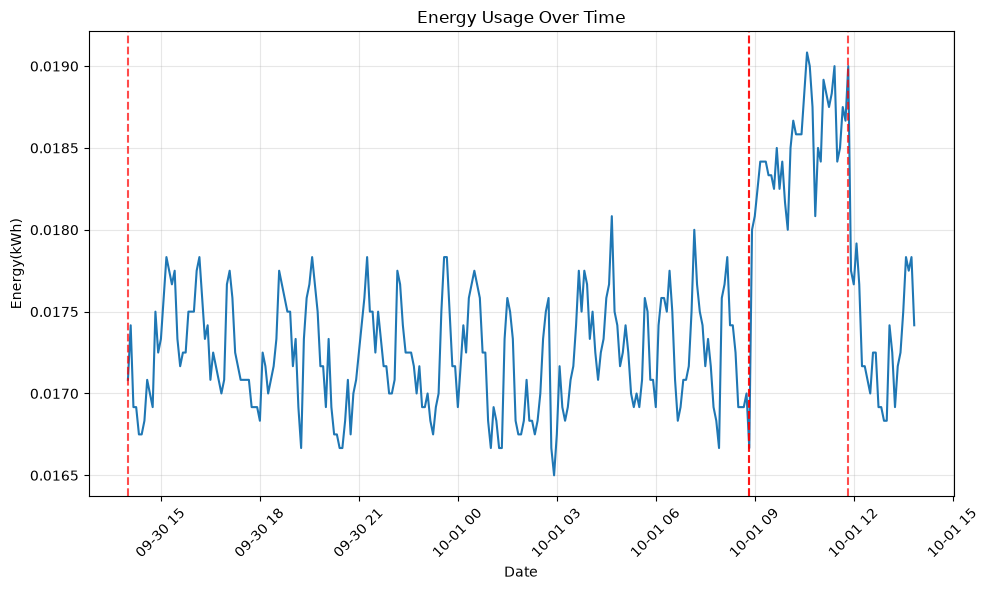

In [118]:
#raw_power_data.plot(x='Date', y='Energy(kWh)', title='Energy Usage Over Time')
#start_time = corresponding_datasets[runNr -1][2]
title = "Energy Usage Over Time"
xcol="Date"
ycol="Energy(kWh)"
start_time_baseline = corresponding_datasets[runNr]["start_time_baseline"]
end_time_baseline = corresponding_datasets[runNr]["end_time_baseline"]
start_time_pipeline = corresponding_datasets[runNr]["start_time_pipeline"]
end_time_pipeline = corresponding_datasets[runNr]["end_time_pipeline"]

timestamps = []
timestamps = [start_time_baseline, end_time_baseline, start_time_pipeline, end_time_pipeline]

plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=None, end=None, timestamps=timestamps)
#plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=start_time_baseline, end=None, timestamps=timestamps)
#plot_energy_usage(power_data, x_col=xcol, y_col=ycol, title=title, start=start_time_baseline, end=end_time_pipeline, timestamps=timestamps)


In [110]:
time_periods = get_time_periods(carbontracker_simpipe_data, start_time_baseline, end_time_baseline)

    get_time_periods -- start and end times present. Assuming baseline period.
     appending baseline period
    get_time_periods -- extracted time periods:
      - baseline: 2026-10-26T16:00:00 to 2026-10-27T07:00:00
      - power-stress(0:0): 2026-10-26 11:37:43 to 2026-10-26 14:37:59


In [111]:
time_periods

[('baseline', '2026-10-26T16:00:00', '2026-10-27T07:00:00'),
 ('power-stress(0:0)', '2026-10-26 11:37:43', '2026-10-26 14:37:59')]